In [1]:
# Importing needed libraries
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Preprocessing

In [48]:
iris_dataset = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv") # downloading the data
iris_dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


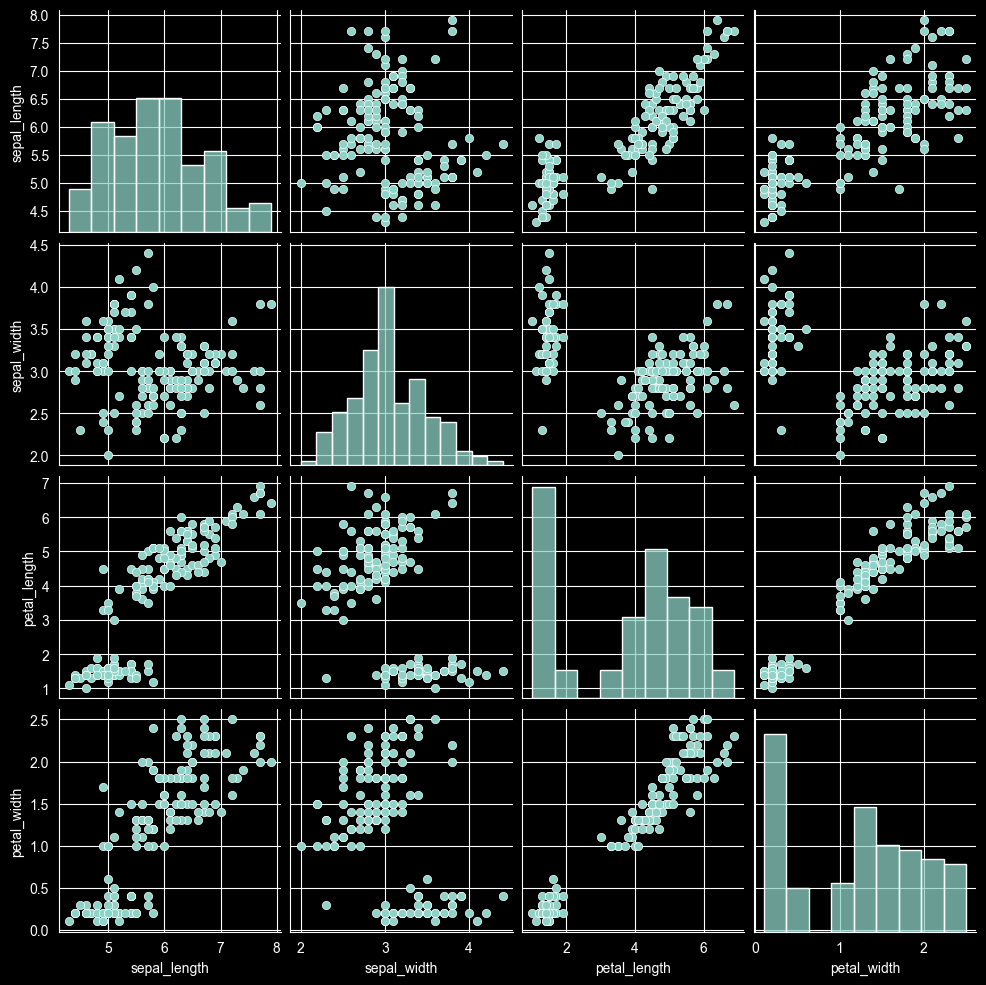

In [49]:
sns.pairplot(iris_dataset) # crating plots that help to see relationships between numerical features
plt.show()

In [50]:
X = iris_dataset.drop(columns="species").values # Splitting feature and target columns
y = iris_dataset["species"]

In [51]:
print(X)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [52]:
print(y)

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: species, Length: 150, dtype: str


In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # splitting into train and test sets with ratio 80/20

In [54]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train) # standardizing features
X_test = scaler.fit_transform(X_test)

# LogisticRegression Model

In [55]:
regression_model = LogisticRegression(max_iter=1000) # Building our model
regression_model.fit(X_train, y_train) # Training the model with our train sets

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [56]:
y_pred = regression_model.predict(X_test) # testing our model with data that it has not seen yet, in order to know how well our model can predict
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

In [57]:
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.9667
Precision: 0.9697
Recall:    0.9667
F1-score:  0.9666


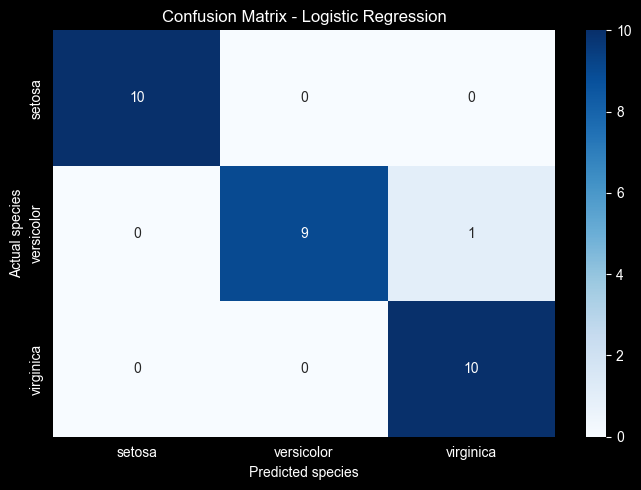

In [58]:
con_matrix = confusion_matrix(y_test, y_pred) # plotting confusion matrix, in order to see how many flowers our model classified correctly and incorrectly for each species

plt.figure(figsize=(7,5))
sns.heatmap(
    con_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=regression_model.classes_,
    yticklabels=regression_model.classes_
)

plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

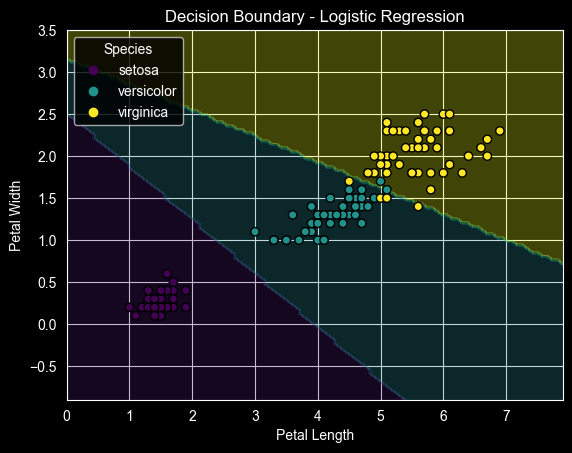

In [72]:
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import make_pipeline

# Our Iris dataset has four features, so we cannot directly plot its full decision boundaries in a 2D graph. Instead, we can visualize two features: petal_length and petal_width

X = iris_dataset[["petal_length", "petal_width"]]
y = iris_dataset["species"]

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X, y)

DecisionBoundaryDisplay.from_estimator(
    model,
    X,
    response_method="predict",
    cmap="viridis",
    alpha=0.3
)

scatter = plt.scatter(X["petal_length"], X["petal_width"], c=y.astype("category").cat.codes,
            cmap="viridis", edgecolors="black")

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Decision Boundary - Logistic Regression")
plt.legend(
    handles = scatter.legend_elements()[0],
    labels=list(y.astype("category").cat.categories),
    title = "Species",
)
plt.show()

# DecisionTreeClassifier Model

In [60]:
tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)

In [62]:
y_pred_tree = tree_model.predict(X_test)

accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree, average="weighted")
recall_tree = recall_score(y_test, y_pred_tree, average="weighted")
f1_tree = f1_score(y_test, y_pred_tree, average="weighted")

In [63]:
print(f"Accuracy:  {accuracy_tree:.4f}")
print(f"Precision: {precision_tree:.4f}")
print(f"Recall:    {recall_tree:.4f}")
print(f"F1-score:  {f1_tree:.4f}")

Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1-score:  0.9333


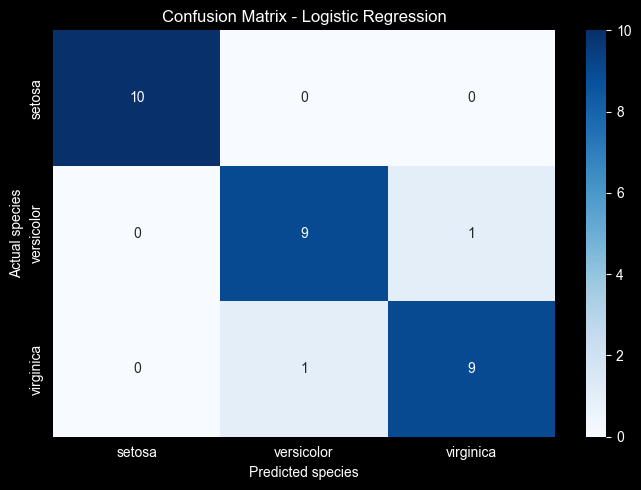

In [64]:
con_matrix_tree = confusion_matrix(y_test, y_pred_tree) # plotting confusion matrix, in order to see how many flowers our model classified correctly and incorrectly for each species

plt.figure(figsize=(7,5))
sns.heatmap(
    con_matrix_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=tree_model.classes_,
    yticklabels=tree_model.classes_
)

plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

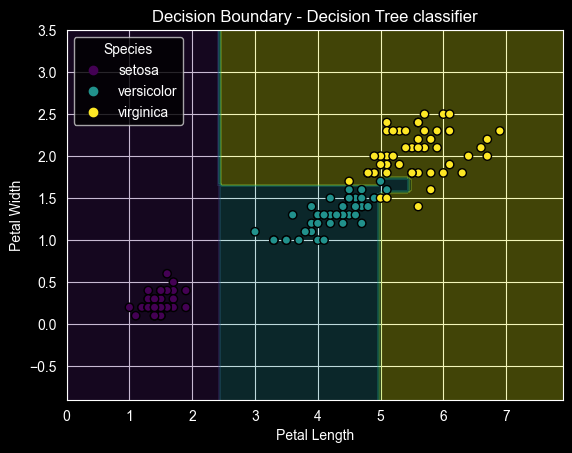

In [73]:
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import make_pipeline

# Our Iris dataset has four features, so we cannot directly plot its full decision boundaries in a 2D graph. Instead, we can visualize two features: petal_length and petal_width

X = iris_dataset[["petal_length", "petal_width"]]
y = iris_dataset["species"]

model_tree = make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=42))
model_tree.fit(X, y)

DecisionBoundaryDisplay.from_estimator(
    model_tree,
    X,
    response_method="predict",
    cmap="viridis",
    alpha=0.3
)

scatter_tree = plt.scatter(X["petal_length"],
            X["petal_width"],
            c=y.astype("category").cat.codes,
            cmap="viridis",
            edgecolors="black"
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Decision Boundary - Decision Tree classifier")
plt.legend(
    handles = scatter_tree.legend_elements()[0],
    labels=list(y.astype("category").cat.categories),
    title = "Species",
)
plt.show()